In [1]:
import os
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.utils as vutils
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from ignite.engine import Engine
from ignite.metrics import FID, InceptionScore

C:\Users\Albert\AppData\Roaming\Python\Python312\site-packages\ignite\handlers\checkpoint.py:16: DeprecationWarning: `TorchScript` support for functional optimizers is deprecated and will be removed in a future PyTorch release. Consider using the `torch.compile` optimizer instead.
  from torch.distributed.optim import ZeroRedundancyOptimizer


In [ ]:
def get_dataloaders(data_dir = 'chest_xray/chest_xray', batch_size = 32, image_size = 256):
    # Makes images compressed to image_size x image_size and then converted to a normalized tensor
    transform = transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    train_dir = os.path.join(data_dir, 'train')
    test_dir = os.path.join(data_dir, 'test')

    train_dataset = datasets.ImageFolder(train_dir, transform = transform)
    test_dataset = datasets.ImageFolder(test_dir, transform = transform)

    # makes the datasets iterables that feed data into the model
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers = 3, persistent_workers = True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers = 3, persistent_workers = True)

    return train_loader, test_loader

In [3]:
class VAE(nn.Module):
    def __init__(self, in_channels = 3, latent_dim = 1024):
        super(VAE, self).__init__()
        self.latent_dim = latent_dim
        hidden_dims = [32, 64, 128, 256, 512]

        #Encoder: maps input to latent space distribution parameters.
        modules = []
        for h_dim in hidden_dims:
            modules.append(
                nn.Sequential(
                    nn.Conv2d(in_channels, out_channels=h_dim,
                              kernel_size=3, stride=2, padding=1),
                    nn.BatchNorm2d(h_dim),
                    nn.LeakyReLU()
                )
            )
            in_channels = h_dim

        self.encoder = nn.Sequential(*modules)
        self.fc_mu = nn.Linear(hidden_dims[-1] * 64, latent_dim)
        self.fc_var = nn.Linear(hidden_dims[-1] * 64, latent_dim)

        #Decoder: reconstructs data from the latent representation.
        self.decoder_input = nn.Linear(latent_dim, hidden_dims[-1] * 256)
        hidden_dims.reverse()

        modules = []
        for i in range(len(hidden_dims) - 1):
            modules.append(
                nn.Sequential(
                    nn.ConvTranspose2d(hidden_dims[i],
                                       hidden_dims[i + 1],
                                       kernel_size=3,
                                       stride=2,
                                       padding=1,
                                       output_padding=1),
                    nn.BatchNorm2d(hidden_dims[i + 1]),
                    nn.LeakyReLU()
                )
            )

        modules.append(
            nn.Sequential(
                nn.Conv2d(hidden_dims[-1], out_channels=3,
                          kernel_size=3, padding=1),
                nn.Tanh()
            )
        )
        self.decoder = nn.Sequential(*modules)

    def encode(self, img):
        latent = self.encoder(img)
        latent = torch.flatten(latent, start_dim=1)
        mu = self.fc_mu(latent)
        log_var = self.fc_var(latent)
        return mu, log_var

    def decode(self, z):
        result = self.decoder_input(z)
        result = result.view(-1, 512, 16, 16)
        result = self.decoder(result)
        return result

    #Reparameterization trick that allows backpropagation through random sampling.
    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std) #independent random number
        z = eps * std + mu
        return z

    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var)
        return self.decode(z), mu, log_var

In [ ]:
# Loss function balances reconstruction accuracy with latent space regularization.
def vae_loss(recon_x, x, mu, log_var):
    reconstruction_error = 0.5 * torch.sum((x - recon_x).pow(2)) #expected log-likelihood
    KL_divergence = 0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
    return -KL_divergence + reconstruction_error #ELBO

def train(data_dir, epochs = 100, batch_size = 64, learning_rate = 0.0003, latent_dim = 1000):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = VAE(latent_dim = latent_dim).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    train_loader, _ = get_dataloaders(data_dir, batch_size)
    loss_history = []

    model.train()
    for epoch in range(epochs):
        epoch_loss = 0
        for batch_idx, (data, _) in enumerate(train_loader):
            data = data.to(device)
            optimizer.zero_grad()

            recon_batch, mu, log_var = model(data)
            loss = vae_loss(recon_batch, data, mu, log_var)

            loss.backward()
            epoch_loss += loss.item()
            optimizer.step()

        avg_loss = epoch_loss / len(train_loader.dataset)
        loss_history.append(avg_loss)
        print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.4f}")

    plt.plot(loss_history)
    plt.title('VAE Training Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.savefig('loss_curve.png')

    # Save hyperparameters to a JSON file for later
    hyperparameters = {
        'epochs': epochs,
        'batch_size': batch_size,
        'learning_rate': learning_rate,
        'latent_dim': latent_dim
    }
    with open('hyperparameters.json', 'w') as f:
        json.dump(hyperparameters, f)

    # Save only the model weights
    torch.save(model.state_dict(), 'vae_model.pth')

#Resizes images to 299 * 299 for InceptionV3
def interpolate(batch):
    batch = ((batch + 1) / 2).clamp(0, 1)
    return F.interpolate(batch, size=(299, 299), mode='bilinear', align_corners=False)

In [ ]:
def generate_samples(model_path='vae_model.pth', config_path='hyperparameters.json', num_images = 5, output_dir='generated_images'):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    with open(config_path, 'r') as f:
        config = json.load(f)

    model = VAE(latent_dim=config['latent_dim']).to(device)
    model.load_state_dict(torch.load(model_path, weights_only=True))
    model.eval()

    os.makedirs(output_dir, exist_ok=True)

    with torch.no_grad():
        random_latent_vectors = torch.randn(num_images, model.latent_dim).to(device)
        generated_images = model.decode(random_latent_vectors)

        # Loop through the batch and save each image individually
        for i in range(num_images):
            img_path = os.path.join(output_dir, f'generated_xray_{i+1:02d}.png')
            vutils.save_image(generated_images[i], img_path, normalize = True, value_range=(-1, 1))

        print(f"Saved {num_images} individual images to the '{output_dir}/' folder.")

In [6]:
def evaluate_model(model_path='vae_model.pth', config_path='hyperparameters.json', data_dir='chest_xray/chest_xray', batch_size = 64):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    with open(config_path, 'r') as f:
        config = json.load(f)

    model = VAE(latent_dim=config['latent_dim']).to(device)
    model.load_state_dict(torch.load(model_path, weights_only=True))

    _, test_loader = get_dataloaders(data_dir, batch_size)

    fid_metric = FID(device=device)
    is_metric = InceptionScore(device=device, output_transform=lambda x: x[0])

    def evaluation_step(engine, batch):
        with torch.no_grad():
            real_batch = batch[0].to(device)
            noise = torch.randn(real_batch.size(0), config['latent_dim'], device=device)
            model.eval()
            fake_batch = model.decode(noise)
            fake = interpolate(fake_batch)
            real = interpolate(real_batch)
            return fake, real

    evaluator = Engine(evaluation_step)
    fid_metric.attach(evaluator, "fid")
    is_metric.attach(evaluator, "is")
    evaluator.run(test_loader, max_epochs=1)

    metrics = evaluator.state.metrics
    fid_score = metrics['fid']
    is_score = metrics['is']

    print(f"FID : {fid_score:4f}")
    print(f"IS : {is_score:4f}")

Epoch 1/100, Loss: 8005.3524
Epoch 2/100, Loss: 3154.0450
Epoch 3/100, Loss: 2671.1102
Epoch 4/100, Loss: 2483.0157
Epoch 5/100, Loss: 2287.3880
Epoch 6/100, Loss: 2196.0493
Epoch 7/100, Loss: 2129.4844
Epoch 8/100, Loss: 2044.5216
Epoch 9/100, Loss: 1999.2937
Epoch 10/100, Loss: 1961.4601
Epoch 11/100, Loss: 1882.3426
Epoch 12/100, Loss: 1864.6927
Epoch 13/100, Loss: 1851.3377
Epoch 14/100, Loss: 1807.7427
Epoch 15/100, Loss: 1756.6316
Epoch 16/100, Loss: 1732.3920
Epoch 17/100, Loss: 1697.8396
Epoch 18/100, Loss: 1648.6111
Epoch 19/100, Loss: 1647.1790
Epoch 20/100, Loss: 1625.6315
Epoch 21/100, Loss: 1565.7847
Epoch 22/100, Loss: 1577.0472
Epoch 23/100, Loss: 1553.0658
Epoch 24/100, Loss: 1535.5990
Epoch 25/100, Loss: 1480.0098
Epoch 26/100, Loss: 1467.2832
Epoch 27/100, Loss: 1463.3270
Epoch 28/100, Loss: 1449.9316
Epoch 29/100, Loss: 1439.6487
Epoch 30/100, Loss: 1422.2716
Epoch 31/100, Loss: 1394.4051
Epoch 32/100, Loss: 1371.3532
Epoch 33/100, Loss: 1342.3779
Epoch 34/100, Loss:

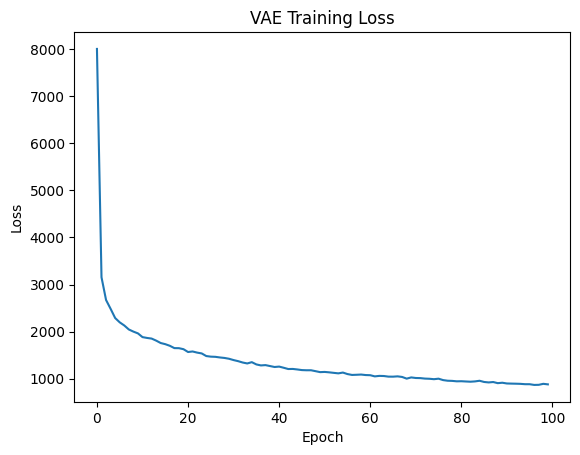

In [7]:
data_path = 'chest_xray/chest_xray'
train(data_dir=data_path, epochs = 100, batch_size = 64)

In [8]:
generate_samples()

Saved 5 individual images to the 'generated_images/' folder.


In [9]:
evaluate_model(model_path = 'vae_model.pth', data_dir = data_path)

FID : 0.133087
IS : 1.675212
